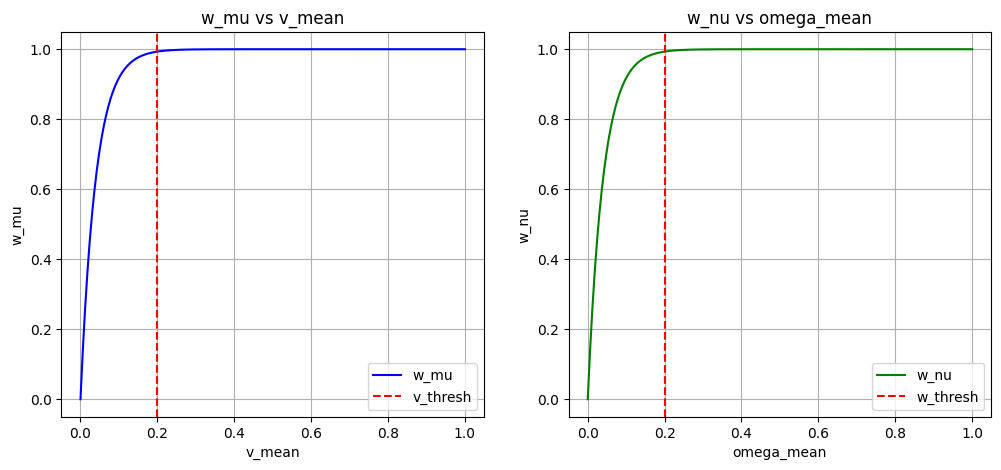

In [7]:
import matplotlib.pyplot as plt
import numpy as np
from data_labeling_pipeline.hyperparameters import v_thresh, w_thresh

v_means = np.linspace(0, 1, 500)
omega_means = np.linspace(0, 1, 500)

w_mus = 1.0 - np.exp(-5.0 * v_means / v_thresh)
w_nus = 1.0 - np.exp(-5.0 * omega_means / w_thresh)


plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(v_means, w_mus, label="w_mu", color="blue")
plt.axvline(v_thresh, color="red", linestyle="--", label="v_thresh")
plt.title("w_mu vs v_mean")
plt.xlabel("v_mean")
plt.ylabel("w_mu")
plt.legend()
plt.grid()
plt.subplot(1, 2, 2)
plt.plot(omega_means, w_nus, label="w_nu", color="green")
plt.axvline(w_thresh, color="red", linestyle="--", label="w_thresh")
plt.title("w_nu vs omega_mean")
plt.xlabel("omega_mean")
plt.ylabel("w_nu")
plt.legend()
plt.grid()
plt.show()


In [8]:
import plotly.graph_objects as go
from data_labeling_pipeline.hyperparameters import max_tie_strengh


## 3D plot: v_mean, omega_mean vs Coupling Strength
def cost_tie(v_mean, omega_mean):
    w_mu = 1.0 - np.exp(-5.0 * v_mean / v_thresh)
    w_nu = 1.0 - np.exp(-5.0 * omega_mean / w_thresh)
    return max_tie_strengh * ((1.0 - w_mu) * w_nu**2 + (1.0 - w_nu) * w_mu**2)


v_means = np.linspace(0, 1, 50)
omega_means = np.linspace(0, 1, 50)
v_grid, omega_grid = np.meshgrid(v_means, omega_means)
coupling_grid = cost_tie(v_grid, omega_grid)
fig = go.Figure(data=[go.Surface(z=coupling_grid, x=v_grid, y=omega_grid)])
fig.update_layout(
    title="v_mean and omega_mean vs Coupling Strength",
    scene=dict(
        xaxis_title="v_mean", yaxis_title="omega_mean", zaxis_title="Coupling Strength"
    ),
)
fig.show()

print(f"{cost_tie(0.5, 0.5)}")

9.689226030166018e-06


In [9]:
# for start in window_starts:
#     end = start + horizon_n
#     U_window = U[start:end]
#     Z_window = Z[start:end]

#     X_opt, m_opt, w_mu, w_nu = rhe.estimate(U_window, Z_window, step_size=step_size)

#     mu_true = np.mean(m_true[start:end, 0])
#     nu_true = np.mean(m_true[start:end, 1])

#     mu_err = abs(m_opt[0] - mu_true)
#     nu_err = abs(m_opt[1] - nu_true)

#     # Weight errors by confidence: well-excited windows matter more
#     # Add small baseline (0.1) so low-excitation windows still contribute
#     weight_mu = max(0.1, w_mu)
#     weight_nu = max(0.1, w_nu)

#     total_weighted_error += weight_mu * mu_err + weight_nu * nu_err
#     total_weight += weight_mu + weight_nu

#     # Optional: include state error (RMSE of X over the window) against ground truth
#     if state_weight > 0:
#         X_true_window = scenario.X_true[start:end]
#         # shape (N,3) -- compute RMSE over all state dims
#         diff = X_opt - X_true_window
#         diff
#         state_rmse = float(np.sqrt(np.mean((X_opt - X_true_window) ** 2)))
#         total_weighted_error += state_weight * state_rmse
#         total_weight += state_weight

In [10]:
import matplotlib.pyplot as plt
from ipywidgets import FloatSlider, interact


def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))


def traversability_score(error, sigmoid_slope, sigmoid_cutoff):
    return sigmoid(-(sigmoid_slope * (error - sigmoid_cutoff)))


v_errors_lin = np.linspace(0, 1, 300) ** 2


def plot_linear_traversability(sigmoid_cutoff, sigmoid_slope):
    """Interactive plot for linear traversability"""
    scores = traversability_score(v_errors_lin, sigmoid_slope, sigmoid_cutoff)

    plt.figure(figsize=(10, 6))
    plt.plot(v_errors_lin, scores, linewidth=2, color="blue")
    plt.axvline(
        sigmoid_cutoff,
        color="red",
        linestyle="--",
        linewidth=2,
        label=f"sigmoid_cutoff={sigmoid_cutoff:.3f}",
    )
    plt.title(
        f"Linear traversability score — sigmoid_slope={sigmoid_slope:.1f}, sigmoid_cutoff={sigmoid_cutoff:.3f}",
        fontsize=14,
    )
    plt.xlabel("error [m²/s²]", fontsize=12)
    plt.ylabel("traversability", fontsize=12)
    plt.ylim(-0.05, 1.05)
    plt.grid(True, alpha=0.3)
    plt.legend(fontsize=11)
    plt.tight_layout()
    plt.show()


interact(
    plot_linear_traversability,
    sigmoid_cutoff=FloatSlider(
        min=0.01, max=0.3, step=0.01, value=0.2, description="sigmoid_cutoff:"
    ),
    sigmoid_slope=FloatSlider(
        min=30, max=80, step=1, value=30, description="sigmoid_slope:"
    ),
)


interactive(children=(FloatSlider(value=0.2, description='sigmoid_cutoff:', max=0.3, min=0.01, step=0.01), Flo…

<function __main__.plot_linear_traversability(sigmoid_cutoff, sigmoid_slope)>

In [11]:
v_errors_ang = np.linspace(0, 1, 300) ** 2


def plot_angular_traversability(sigmoid_cutoff, sigmoid_slope):
    """Interactive plot for angular traversability"""
    scores = traversability_score(v_errors_ang, sigmoid_slope, sigmoid_cutoff)

    plt.figure(figsize=(10, 6))
    plt.plot(v_errors_ang, scores, linewidth=2, color="green")
    plt.axvline(
        sigmoid_cutoff,
        color="orange",
        linestyle="--",
        linewidth=2,
        label=f"sigmoid_cutoff={sigmoid_cutoff:.3f}",
    )
    plt.title(
        f"Angular traversability score — sigmoid_slope={sigmoid_slope:.1f}, sigmoid_cutoff={sigmoid_cutoff:.3f}",
        fontsize=14,
    )
    plt.xlabel("error [rad²/s²]", fontsize=12)
    plt.ylabel("traversability", fontsize=12)
    plt.ylim(-0.05, 1.05)
    plt.grid(True, alpha=0.3)
    plt.legend(fontsize=11)
    plt.tight_layout()
    plt.show()


interact(
    plot_angular_traversability,
    sigmoid_cutoff=FloatSlider(
        min=0.005, max=0.2, step=0.005, value=0.2, description="sigmoid_cutoff:"
    ),
    sigmoid_slope=FloatSlider(
        min=30, max=100, step=5, value=30, description="sigmoid_slope:"
    ),
)


interactive(children=(FloatSlider(value=0.2, description='sigmoid_cutoff:', max=0.2, min=0.005, step=0.005), F…

<function __main__.plot_angular_traversability(sigmoid_cutoff, sigmoid_slope)>